# Day 48 — Forward propagation, backpropagation, and gradient descent

**Goal:** calculate one complete training step by hand and in NumPy. We use the same 2-input, 2-hidden-unit, 1-output network throughout. We then train a tiny model on four examples. Run the cells in order and change values to test your understanding.

**Day 47 link:** a sigmoid turns the final score into a binary probability; binary cross entropy (BCE) measures its error.

## 1. The learning loop

1. **Forward:** compute $z^{(1)}=W^{(1)}x+b^{(1)}$, $a^{(1)}=\sigma(z^{(1)})$, $z^{(2)}=W^{(2)}a^{(1)}+b^{(2)}$, and $p=\sigma(z^{(2)})$.
2. **Loss:** $L=-[y\log p+(1-y)\log(1-p)]$.
3. **Backward:** calculate each parameter's derivative by the chain rule.
4. **Update:** $\theta\leftarrow\theta-\eta\nabla_\theta L$.

We store the intermediate $z$ and $a$ values because backpropagation reuses them.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=6, suppress=True)

def sigmoid(z):
    # Stable for both large positive and large negative inputs.
    z = np.asarray(z, dtype=float)
    out = np.empty_like(z)
    positive = z >= 0
    out[positive] = 1 / (1 + np.exp(-z[positive]))
    exp_z = np.exp(z[~positive])
    out[~positive] = exp_z / (1 + exp_z)
    return out

def bce_from_logit(z, y):
    # softplus(z) - y*z; works without log(0).
    return np.logaddexp(0, z) - y * z

print('sigmoid(0) =', sigmoid(0.0))

sigmoid(0) = 0.5


### Shapes used below

$x\in\mathbb R^2$, $W^{(1)}\in\mathbb R^{2\times2}$, $b^{(1)}\in\mathbb R^2$, $W^{(2)}\in\mathbb R^{1\times2}$, and $b^{(2)}$ is a scalar. **A parameter and its gradient have the same shape.**

In [2]:
x = np.array([1., 2.])
y = 1.
W1 = np.array([[0.2, -0.3], [0.4, 0.1]])
b1 = np.array([0.1, -0.2])
W2 = np.array([0.7, -0.5])
b2 = 0.1
print('shapes:', x.shape, W1.shape, b1.shape, W2.shape)

shapes: (2,) (2, 2) (2,) (2,)


## 2. Forward propagation

Each row of $W^{(1)}$ belongs to one hidden neuron. For the first neuron, $z_1^{(1)}=0.2(1)-0.3(2)+0.1=-0.3$. For the second, $z_2^{(1)}=0.4(1)+0.1(2)-0.2=0.4$. Apply sigmoid separately to both scores.

In [3]:
z1 = W1 @ x + b1
a1 = sigmoid(z1)
z2 = float(W2 @ a1 + b2)
p = float(sigmoid(z2))
loss = float(bce_from_logit(z2, y))
print('z1 =', z1, 'a1 =', a1)
print(f'z2 = {z2:.6f}, p = {p:.6f}, BCE = {loss:.6f}')
assert np.allclose(z1, [-.3, .4])
assert np.isclose(loss, .6450874099063771)

z1 = [-0.3  0.4] a1 = [0.425557 0.598688]
z2 = 0.098546, p = 0.524617, BCE = 0.645087


The final probability is about $0.52462$ for the target $y=1$. BCE is about $0.64509$. A threshold of 0.5 would predict class 1, but the loss still records the weak confidence.

## 3. What a gradient means

The derivative $\partial L/\partial w$ is the local change in loss if $w$ increases slightly. Gradient descent subtracts this derivative: $w_{new}=w-\eta\,\partial L/\partial w$. A negative derivative makes the weight increase. The derivative depends on the current weights and this example.

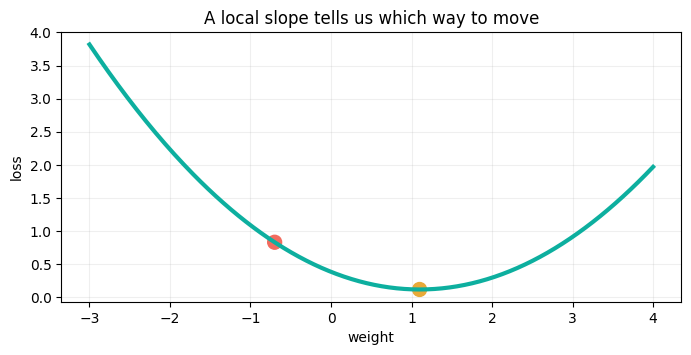

In [4]:
ws = np.linspace(-3, 4, 300)
ls = 0.22 * (ws - 1.1)**2 + .12
plt.figure(figsize=(8, 3.5))
plt.plot(ws, ls, lw=3, color='#0daf9f')
plt.scatter([-.7, 1.1], [0.22*(-.7-1.1)**2+.12, .12], c=['#f26b5e','#e9aa38'], s=100)
plt.xlabel('weight'); plt.ylabel('loss'); plt.title('A local slope tells us which way to move')
plt.grid(alpha=.2); plt.show()

## 4. Backpropagation: start at the output

For sigmoid plus BCE, the chain rule simplifies to $\delta^{(2)}=\partial L/\partial z^{(2)}=p-y$. The separate factors are $\partial L/\partial p=-y/p+(1-y)/(1-p)$ and $\partial p/\partial z^{(2)}=p(1-p)$; multiplying and simplifying gives $p-y$.

Because $z^{(2)}=W^{(2)}a^{(1)}+b^{(2)}$, $\nabla_{W^{(2)}}L=\delta^{(2)}a^{(1)}$ and $\partial L/\partial b^{(2)}=\delta^{(2)}$.

In [5]:
delta2 = p - y
dW2 = delta2 * a1
db2 = delta2
print('delta2 =', delta2)
print('dW2 =', dW2, 'db2 =', db2)

delta2 = -0.47538331659281075
dW2 = [-0.202303 -0.284606] db2 = -0.47538331659281075


## 5. Move the sensitivity to the hidden layer

Sigmoid's derivative is $\sigma'(z)=\sigma(z)(1-\sigma(z))$. For each hidden neuron, multiply the upstream output error by its outgoing weight and by the neuron's sigmoid derivative:

$$\delta^{(1)}=\big((W^{(2)})^T\delta^{(2)}\big)\odot\big(a^{(1)}(1-a^{(1)})\big).$$

The $\odot$ operation is elementwise. The first layer's weight gradient is the outer product $\nabla_{W^{(1)}}L=\delta^{(1)}x^T$; its bias gradient is $\delta^{(1)}$.

In [6]:
sigmoid_prime_z1 = a1 * (1 - a1)
delta1 = W2 * delta2 * sigmoid_prime_z1
dW1 = np.outer(delta1, x)
db1 = delta1.copy()
print("sigmoid'(z1) =", sigmoid_prime_z1)
print('delta1 =', delta1)
print('dW1 =\n', dW1)
print('db1 =', db1)
assert dW1.shape == W1.shape and dW2.shape == W2.shape

sigmoid'(z1) = [0.244458 0.240261]
delta1 = [-0.081348  0.057108]
dW1 =
 [[-0.081348 -0.162696]
 [ 0.057108  0.114216]]
db1 = [-0.081348  0.057108]


### Follow one path by hand

$\partial L/\partial W^{(1)}_{1,2}=\delta^{(1)}_1 x_2=(-0.08135)(2)=-0.16270$. The gradient includes the input feature **and** the upstream output weight through $\delta^{(1)}_1$.

## 6. Check the gradients numerically

For one scalar parameter $w$, the centered finite difference is $[L(w+\varepsilon)-L(w-\varepsilon)]/(2\varepsilon)$. It should nearly match backpropagation. This check is for debugging, not for routine training.

In [7]:
def forward_one(W1_, b1_, W2_, b2_, x_=x, y_=y):
    hidden = sigmoid(W1_ @ x_ + b1_)
    logit = float(W2_ @ hidden + b2_)
    return float(bce_from_logit(logit, y_))

eps = 1e-5
checks = []
for i in range(2):
    for j in range(2):
        plus, minus = W1.copy(), W1.copy()
        plus[i,j] += eps; minus[i,j] -= eps
        numeric = (forward_one(plus,b1,W2,b2)-forward_one(minus,b1,W2,b2))/(2*eps)
        checks.append(abs(numeric-dW1[i,j]))
        print(f'W1[{i},{j}]  analytic {dW1[i,j]: .8f}  numeric {numeric: .8f}')
assert max(checks) < 1e-8

W1[0,0]  analytic -0.08134798  numeric -0.08134798
W1[0,1]  analytic -0.16269596  numeric -0.16269596
W1[1,0]  analytic  0.05710798  numeric  0.05710798
W1[1,1]  analytic  0.11421595  numeric  0.11421595


## 7. Apply one simultaneous update

Use the *old* parameters for **all** gradients, then update every parameter with $\eta=0.1$. Recompute the forward pass to measure the resulting loss. One example's loss falling is useful as a calculation check; it does not prove generalization.

In [8]:
eta = .1
W1_new = W1 - eta*dW1
b1_new = b1 - eta*db1
W2_new = W2 - eta*dW2
b2_new = b2 - eta*db2
new_loss = forward_one(W1_new,b1_new,W2_new,b2_new)
new_p = float(sigmoid(float(W2_new @ sigmoid(W1_new@x+b1_new)+b2_new)))
print('new W1 =\n', W1_new)
print('new b1 =', b1_new)
print('new W2 =', W2_new, 'new b2 =', b2_new)
print(f'old loss {loss:.6f} -> new loss {new_loss:.6f}; new p {new_p:.6f}')
assert np.isclose(new_loss, .6052593176438127)

new W1 =
 [[ 0.208135 -0.28373 ]
 [ 0.394289  0.088578]]
new b1 = [ 0.108135 -0.205711]
new W2 = [ 0.72023  -0.471539] new b2 = 0.1475383316592811
old loss 0.645087 -> new loss 0.605259; new p 0.545933


## 8. Minibatches and epochs

For a batch of $m$ examples, minimize $J(\theta)=\frac1m\sum_i L_i(\theta)$ and average the per-example gradients. An **epoch** uses every training example once. Shuffling the examples between epochs helps minibatches vary. In the next cell the four training examples encode AND: only $[1,1]$ has target 1.

In [9]:
X = np.array([[0.,0.],[0.,1.],[1.,0.],[1.,1.]])
Y = np.array([0.,0.,0.,1.])
rng = np.random.default_rng(42)
Wa = rng.normal(0,.3,(3,2)); ba = np.zeros(3)
Wb = rng.normal(0,.3,3); bb = 0.

def batch_step(X,Y,Wa,ba,Wb,bb,eta):
    # Rows are examples in this implementation: X has shape (m,2).
    z = X @ Wa.T + ba            # (m,3)
    a = sigmoid(z)               # (m,3)
    logits = a @ Wb + bb         # (m,)
    probs = sigmoid(logits)      # (m,)
    batch_loss = float(np.mean(bce_from_logit(logits,Y)))
    dlogit = (probs-Y)/len(Y)    # divide by m exactly once
    gWb = a.T @ dlogit           # (3,)
    gbb = dlogit.sum()
    dz = np.outer(dlogit,Wb)*a*(1-a)  # (m,3)
    gWa = dz.T @ X               # (3,2)
    gba = dz.sum(axis=0)         # (3,)
    return batch_loss,(Wa-eta*gWa,ba-eta*gba,Wb-eta*gWb,bb-eta*gbb)

history=[]
for epoch in range(2500):
    Lbatch,(Wa,ba,Wb,bb)=batch_step(X,Y,Wa,ba,Wb,bb,1.0)
    history.append(Lbatch)
probs=sigmoid(sigmoid(X @ Wa.T+ba) @ Wb+bb)
print('probabilities:',probs.round(3),'targets:',Y)
print('loss:',history[0], '->',history[-1])
assert history[-1]<history[0]

probabilities: [0.    0.001 0.001 0.997] targets: [0. 0. 0. 1.]
loss: 0.6856143911765173 -> 0.0012042085773141954


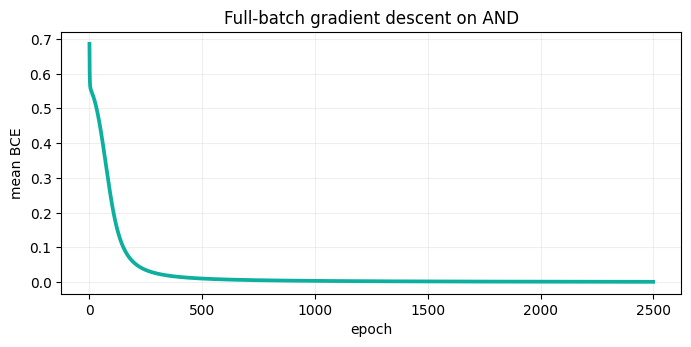

In [10]:
plt.figure(figsize=(8,3.4))
plt.plot(history,color='#0daf9f',linewidth=2.7)
plt.xlabel('epoch');plt.ylabel('mean BCE');plt.title('Full-batch gradient descent on AND')
plt.grid(alpha=.2);plt.show()

## 9. When the chain becomes difficult

Multiplying many small derivatives can make early-layer gradients tiny (**vanishing gradients**); multiplying large factors can make them huge (**exploding gradients**). ReLU hidden layers, suitable initialization, skip connections, normalization, and sometimes gradient clipping can help, depending on the model. ReLU has derivative 0 for negative scores, 1 for positive scores, and needs a chosen subgradient at 0.

**Implementation note:** modern autodiff frameworks record a graph of operations and apply these same local derivatives in reverse. The mathematical gradient is still the quantity used by the optimizer.

## Recap

- Forward values are needed again during backpropagation.
- Output error for **sigmoid + BCE** is $p-y$. It is not a universal formula for every activation and loss.
- Hidden errors multiply upstream sensitivities by outgoing weights and local activation derivatives.
- Weight gradients have the same shape as their weight matrices.
- Update parameters with the negative gradient, then evaluate on held-out data.